# Traffic generation

This notebook builds the traffic generator step by step and checks generated traffic against the real data.

The generator has two layers:

1. **Hourly counts (this notebook):** a statistical model fitted on one junction's history produces the number of vehicles per hour.
2. **Road-level demand (planned):** splits those totals across roads and turns. This notebook will be extended to show it.

Run `uv run python scripts/download_kaggle_data.py` first to get the data. The logic lives in the `trafficgen` package. The notebook only calls it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from trafficgen import MeanProfileModel, StatisticalCountModel, load_config, load_counts
from trafficgen.validation import realism_scores, sample_many, statistics_table

CONFIG_PATH = Path("../configs/traffic.toml")
RUNS = 40
SEED = 0

REAL = {"color": "#2a78d6", "label": "Real", "linestyle": "-"}
STATISTICAL = {"color": "#eb6834", "label": "Statistical model", "linestyle": "--"}
BASELINE = {"color": "#1baf7a", "label": "Baseline", "linestyle": ":"}

plt.rcParams.update(
    {
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 1.8,
        "legend.frameon": False,
    }
)


def junction_grid(title, ylabel, xlabel):
    """Create one panel per junction with independent y axes."""
    figure, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True, layout="constrained")
    figure.suptitle(title, x=0.01, ha="left", fontsize=13)
    figure.supylabel(ylabel, fontsize=10, color="#52514e")
    figure.supxlabel(xlabel, fontsize=10, color="#52514e")
    return figure, dict(zip(counts, axes.flat, strict=True))


def add_legend(figure, axis):
    """Add one legend above the panels of a figure."""
    handles, labels = axis.get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper right", ncols=len(labels))

## 1. The data

Each junction has its own file with two columns, `datetime` and `vehicles`, with no directions, lanes or vehicle types. Here the files come from the Kaggle dataset, which covers four junctions, but any file in this format works. J4 has only six months of data.

In [2]:
config = load_config(CONFIG_PATH)
counts = {junction.id: load_counts(junction.data).astype(float) for junction in config.junctions}

pd.DataFrame(
    {
        junction: {
            "first hour": series.index.min(),
            "last hour": series.index.max(),
            "hours": len(series),
            "mean": round(series.mean(), 1),
            "max": series.max(),
        }
        for junction, series in counts.items()
    }
).T

,first hour,last hour,hours,mean,max
J1,2015-11-01 00:00:00,2017-06-30 23:00:00,14592,45.1,156.0
J2,2015-11-01 00:00:00,2017-06-30 23:00:00,14592,14.3,48.0
J3,2015-11-01 00:00:00,2017-06-30 23:00:00,14592,13.7,180.0
J4,2017-01-01 00:00:00,2017-06-30 23:00:00,4344,7.3,36.0


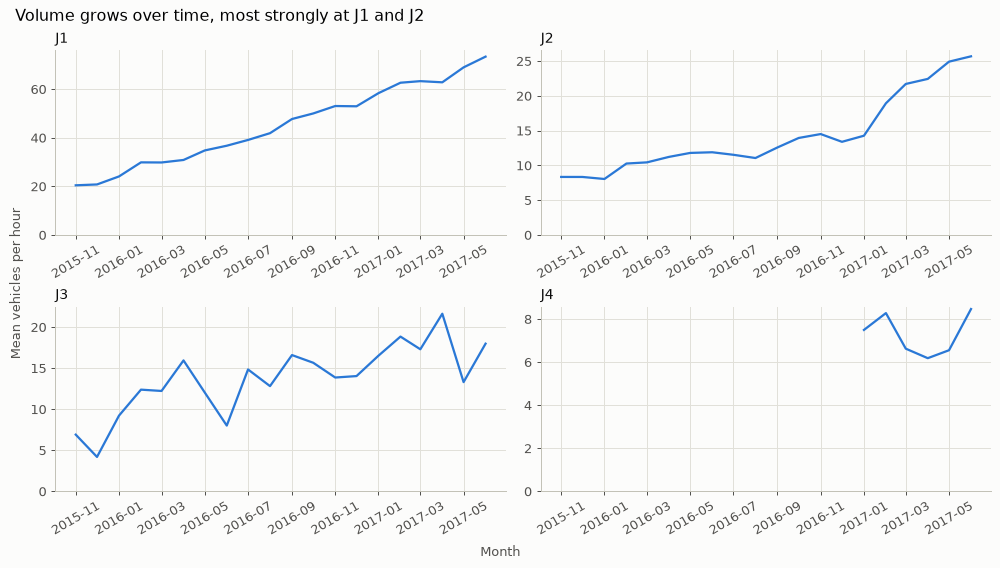

In [3]:
figure, panels = junction_grid(
    "Volume grows over time, most strongly at J1 and J2", "Mean vehicles per hour", "Month"
)
for junction, axis in panels.items():
    monthly = counts[junction].resample("MS").mean()
    axis.plot(monthly.index, monthly.to_numpy(), color=REAL["color"])
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True, rotation=30)
plt.show()

## 2. The statistical model

On the `log(1 + count)` scale, the model is:

```
y[t] = level[t] + profile[weekday, hour] + noise[t]
```

- **Level:** a four week moving average. Inside the data period it follows the fitted growth. Outside it, the level stays flat, because there is too little data to extrapolate growth or separate it from the time of year.
- **Profile:** the average per weekday and hour.
- **Noise:** random one week blocks of the real remaining noise (a block bootstrap), which keeps bursts over several days.

The baseline is simpler: the average per weekday and hour with Poisson noise, ignoring growth. Sources are listed in the docstrings of `trafficgen.models`.

In [4]:
statistical = {junction: StatisticalCountModel().fit(series) for junction, series in counts.items()}
baseline = {junction: MeanProfileModel().fit(series) for junction, series in counts.items()}

### Are the junctions independent?

Raw counts correlate strongly, but mostly because of shared growth and shared daily rhythm. What remains after removing them is what independent models would miss.

In [5]:
raw = pd.DataFrame(counts).corr().round(2)
remaining = pd.DataFrame({j: model.noise_ for j, model in statistical.items()}).corr().round(2)
pd.concat({"raw counts": raw, "remaining noise": remaining}, axis=1)

raw counts                   remaining noise                  
           J1    J2    J3    J4              J1    J2    J3    J4
J1       1.00  0.87  0.53  0.59            1.00  0.25  0.19  0.18
J2       0.87  1.00  0.43  0.40            0.25  1.00  0.15  0.07
J3       0.53  0.43  1.00  0.49            0.19  0.15  1.00  0.19
J4       0.59  0.40  0.49  1.00            0.18  0.07  0.19  1.00

The noise correlations are low, so modelling junctions independently is a reasonable simplification. The data cannot show how the junctions are connected: it has no road information, and crossing a block takes far less than the hourly resolution.

## 3. Generated traffic compared with the real data

Every model below generates traffic for the same hours as the real data, using 40 random seeds where more than one is needed. These checks use the training data, so they show the quality of the fit, not performance on unseen dates.

In [6]:
samples = {
    "Statistical model": {
        j: sample_many(m, counts[j].index, RUNS, seed=SEED) for j, m in statistical.items()
    },
    "Baseline": {j: sample_many(m, counts[j].index, RUNS, seed=SEED) for j, m in baseline.items()},
}

### One example week

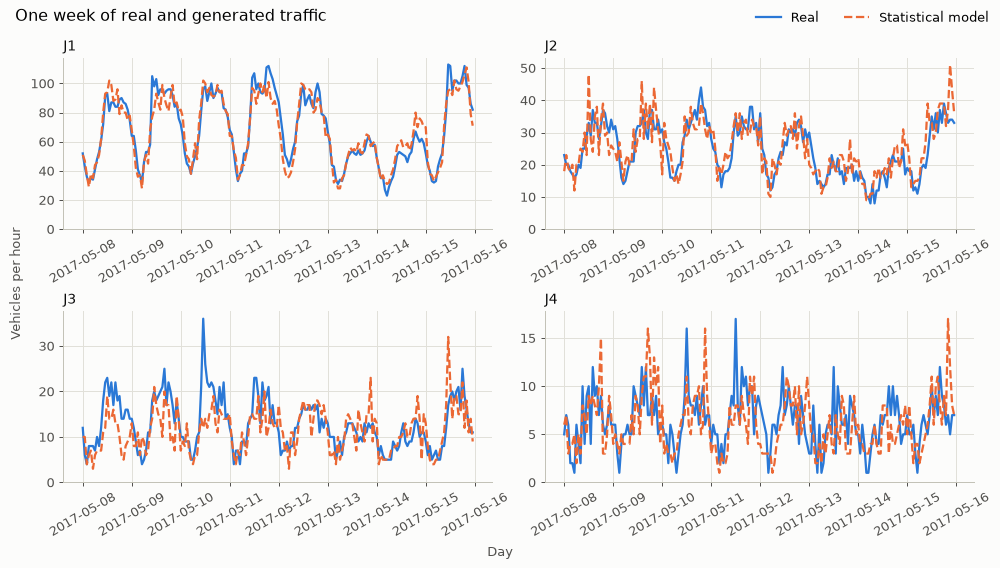

In [7]:
WEEK_START, WEEK_END = "2017-05-08", "2017-05-15"

figure, panels = junction_grid("One week of real and generated traffic", "Vehicles per hour", "Day")
for junction, axis in panels.items():
    real = counts[junction][WEEK_START:WEEK_END]
    generated = samples["Statistical model"][junction][0][WEEK_START:WEEK_END]
    axis.plot(real.index, real.to_numpy(), **REAL)
    axis.plot(generated.index, generated.to_numpy(), **STATISTICAL)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True, rotation=30)
add_legend(figure, axis)
plt.show()

### Daily and weekly profiles

The baseline matches the average day by construction, so its line is hidden behind the others.

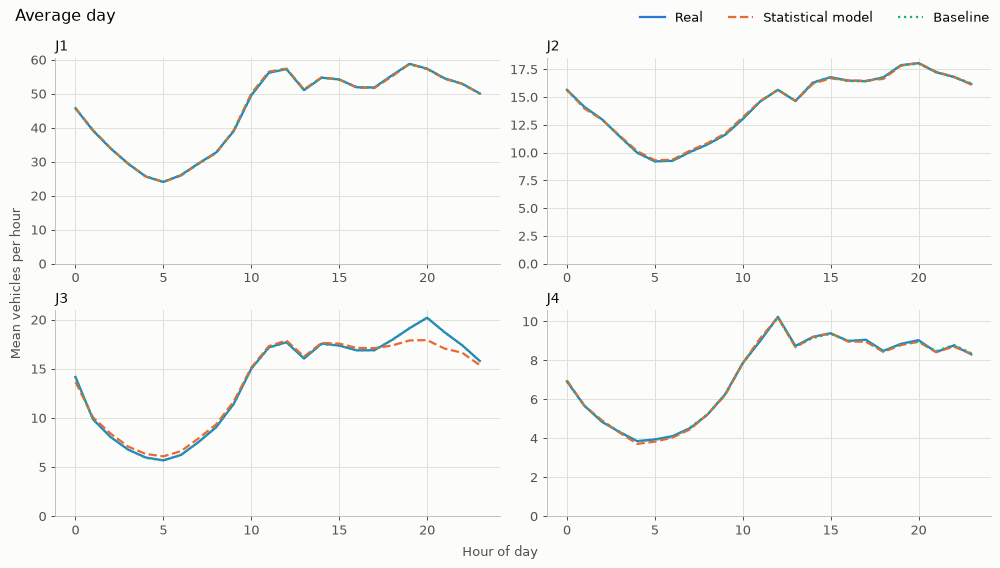

In [8]:
figure, panels = junction_grid("Average day", "Mean vehicles per hour", "Hour of day")
for junction, axis in panels.items():
    real = counts[junction]
    axis.plot(real.groupby(real.index.hour).mean(), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        generated = samples[name][junction].stack()
        hours = generated.index.get_level_values(0).hour
        axis.plot(generated.groupby(hours).mean(), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure, axis)
plt.show()

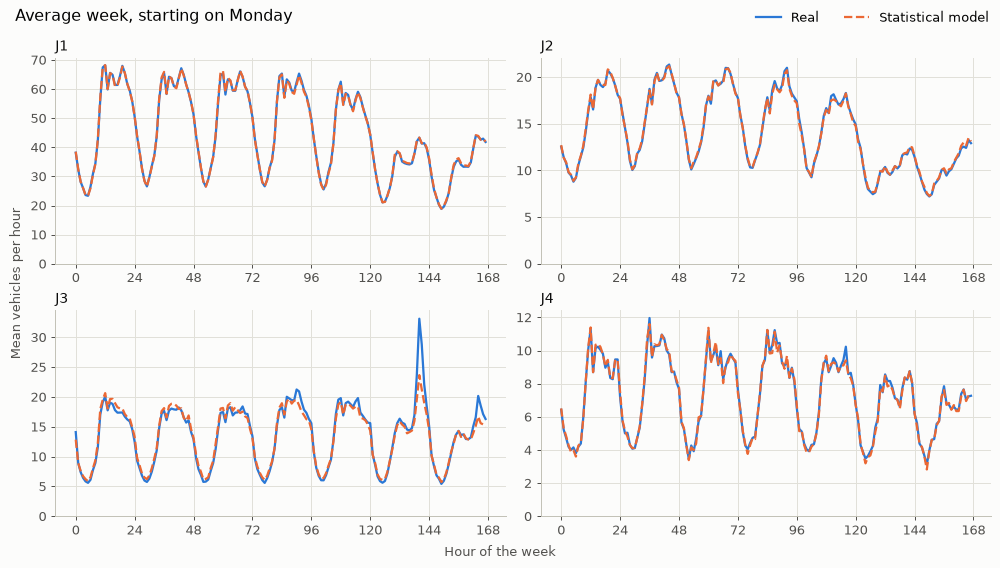

In [9]:
def weekly_profile(series):
    """Average a series for each hour of the week."""
    return series.groupby(series.index.day_of_week * 24 + series.index.hour).mean()


figure, panels = junction_grid(
    "Average week, starting on Monday", "Mean vehicles per hour", "Hour of the week"
)
for junction, axis in panels.items():
    generated = samples["Statistical model"][junction].mean(axis=1)
    axis.plot(weekly_profile(counts[junction]), **REAL)
    axis.plot(weekly_profile(generated), **STATISTICAL)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_xticks(range(0, 169, 24))
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure, axis)
plt.show()

### Distributions

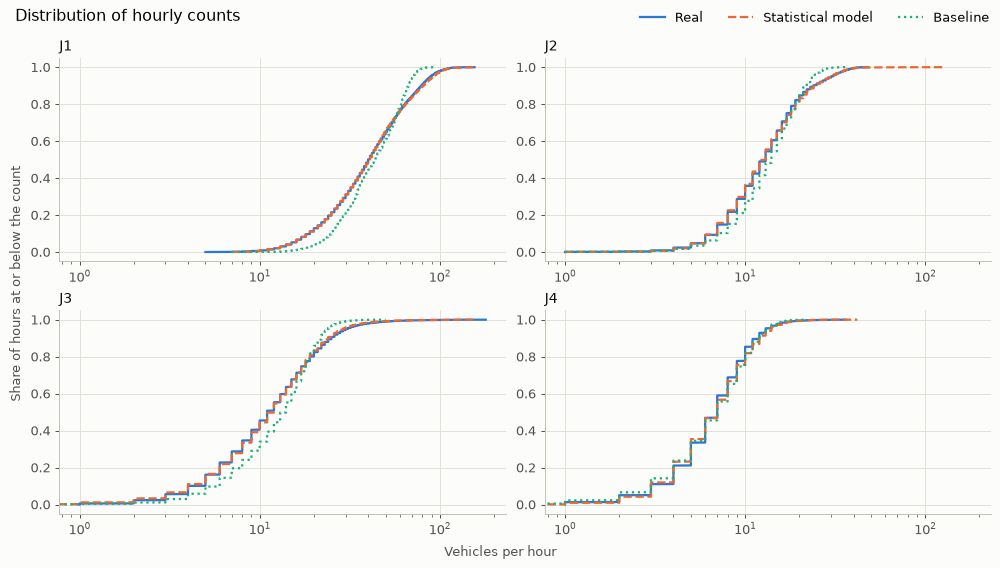

In [10]:
def empirical_cdf(values):
    """Return the sorted values and their cumulative shares."""
    ordered = np.sort(values)
    return ordered, np.arange(1, len(ordered) + 1) / len(ordered)


figure, panels = junction_grid(
    "Distribution of hourly counts", "Share of hours at or below the count", "Vehicles per hour"
)
for junction, axis in panels.items():
    axis.plot(*empirical_cdf(counts[junction].to_numpy()), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        axis.plot(*empirical_cdf(samples[name][junction][0].to_numpy()), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.tick_params(axis="x", labelbottom=True)
    axis.set_xscale("log")
add_legend(figure, axis)
plt.show()

### Autocorrelation

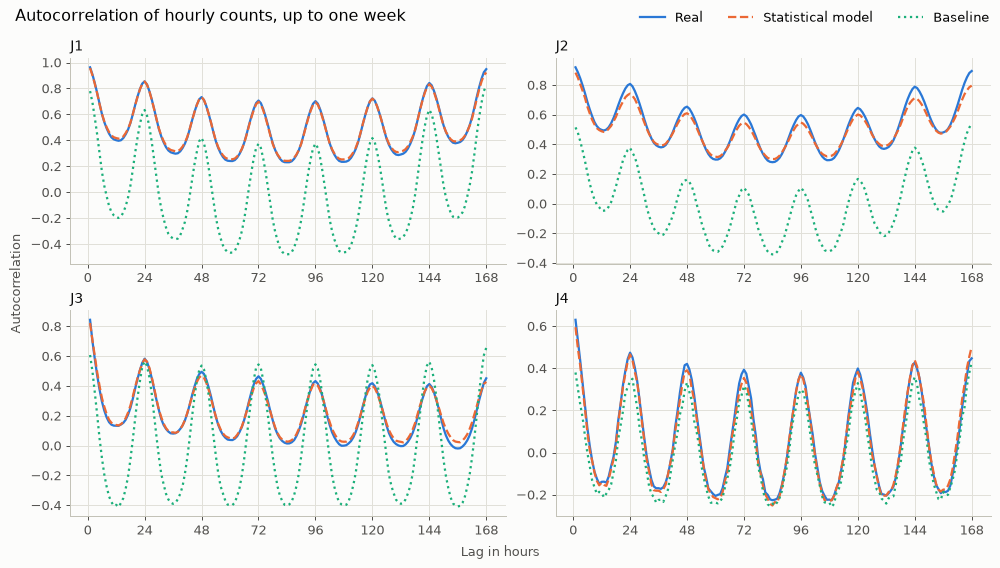

In [11]:
LAGS = range(1, 169)


def autocorrelations(series):
    """Return the autocorrelation of a series at every lag up to one week."""
    return [series.autocorr(lag) for lag in LAGS]


figure, panels = junction_grid(
    "Autocorrelation of hourly counts, up to one week", "Autocorrelation", "Lag in hours"
)
for junction, axis in panels.items():
    axis.plot(LAGS, autocorrelations(counts[junction]), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        axis.plot(LAGS, autocorrelations(samples[name][junction][0]), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_xticks(range(0, 169, 24))
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure, axis)
plt.show()

### Statistical comparison

Significance tests would flag almost any small difference with this many autocorrelated hours, so the tables report the sizes of differences instead of p-values.

- **wasserstein:** average vehicles per hour separating the two distributions. Lower is better.
- **ks:** largest gap between the two cumulative distributions, from 0 to 1. Lower is better.
- **daily and weekly profile error:** average profile difference relative to the mean count. Lower is better.
- **coverage_80:** share of real hours inside the central 80% of generated values. It should be close to 0.80.

In [12]:
pd.DataFrame(
    {
        (name, junction): realism_scores(counts[junction], samples[name][junction])
        for name in samples
        for junction in counts
    }
).T.round(3)

wasserstein     ks  daily_profile_error  \
Statistical model J1        0.418  0.012                0.007   
                  J2        0.227  0.016                0.010   
                  J3        0.442  0.021                0.042   
                  J4        0.188  0.030                0.023   
Baseline          J1        5.723  0.105                0.004   
                  J2        1.420  0.078                0.009   
                  J3        2.382  0.114                0.009   
                  J4        0.333  0.037                0.022   

                      weekly_profile_error  coverage_80  
Statistical model J1                 0.012        0.801  
                  J2                 0.021        0.836  
                  J3                 0.065        0.808  
                  J4                 0.056        0.843  
Baseline          J1                 0.012        0.287  
                  J2                 0.023        0.621  
                  J3                 0.023        0.590  
                  J4                 0.058        0.877

Real and generated statistics per junction for the statistical model, with the range covering 90% of generated series:

In [13]:
pd.concat(
    {
        junction: statistics_table(counts[junction], samples["Statistical model"][junction])
        for junction in counts
    }
).round(2)

real  generated  generated_p05  generated_p95
J1 mean       45.05      45.07          44.76          45.43
   std        23.01      23.14          22.59          23.68
   p50        40.00      40.55          40.00          41.00
   p90        79.00      79.92          79.00          81.00
   p99       108.09     106.86         103.95         110.00
   max       156.00     156.40         138.00         172.10
   acf_1h      0.96       0.95           0.95           0.96
   acf_24h     0.85       0.85           0.84           0.86
   acf_168h    0.95       0.93           0.92           0.94
J2 mean       14.25      14.27          14.14          14.38
   std         7.40       7.51           7.28           7.91
   p50        13.00      12.81          12.00          13.00
   p90        24.00      24.52          24.00          25.00
   p99        38.00      38.13          37.00          39.14
   max        48.00      74.40          51.95         130.15
   acf_1h      0.92       0.87           0.87           0.88
   acf_24h     0.81       0.76           0.73           0.78
   acf_168h    0.89       0.82           0.78           0.85
J3 mean       13.69      13.56          13.12          13.95
   std        10.44       9.54           8.63          10.23
   p50        11.00      11.78          11.00          12.00
   p90        25.00      24.32          23.00          25.05
   p99        51.00      47.33          42.00          51.19
   max       180.00     146.65         110.70         197.10
   acf_1h      0.84       0.82           0.80           0.83
   acf_24h     0.58       0.58           0.55           0.61
   acf_168h    0.45       0.43           0.38           0.49
J4 mean        7.25       7.22           7.09           7.35
   std         3.52       3.50           3.32           3.70
   p50         7.00       7.00           7.00           7.00
   p90        12.00      11.98          12.00          12.00
   p99        18.00      17.30          16.54          18.57
   max        36.00      33.20          25.90          42.00
   acf_1h      0.63       0.56           0.54           0.60
   acf_24h     0.47       0.45           0.42           0.48
   acf_168h    0.45       0.47           0.44           0.50

### Results

The statistical model reproduces the real distribution far better than the baseline, because the baseline ignores growth and treats every hour as independent:

- **Distribution:** the Wasserstein distance is at most 0.44 vehicles per hour, against up to 5.72 for the baseline.
- **Spread:** the coverage of the 80% range is 0.80 to 0.84, against 0.29 to 0.88 for the baseline.
- **Autocorrelation:** it follows the real curves closely, including the daily and weekly cycles. The baseline falls well below them on J1, J2 and J3.

Averages are not where the baseline loses. It matches average profiles by construction, so it is hidden behind the other lines in the average day chart, and its profile errors on J3 are lower.

Known limits of the statistical model:

- **J3 bursts:** the largest bursts are underestimated (std 9.54 against 10.44, 99th percentile 47 against 51). The Saturday evening peak is the clearest case, at about 24 against 33 vehicles per hour. Averaging on the log scale gives such rare bursts less weight.
- **J2 extreme hours:** the highest generated hours go beyond anything in the data (a typical maximum of 74 against 48), because noise from quiet hours can land on busy ones. They are rare: the 99th percentile still matches at 38.
- **Fit only:** these checks use the training data. They say nothing about how well the model would predict new dates, which is not its purpose. Future dates hold the level flat.

## 4. Using the generator

`build_generators` fits one model per junction from the config. `sample` takes whole hours, including the start and excluding the end. Dates outside the data work too, with the level held at its last fitted value. `scale` multiplies the volume.

The same works from the command line:

```bash
uv run python scripts/generate_traffic.py --junction J1 --start 2027-07-05T00:00 --end 2027-07-05T06:00 --seed 42
```

In [14]:
statistical["J1"].sample("2027-07-05 00:00", "2027-07-05 06:00", seed=42).to_frame()

,vehicles
2027-07-05 00:00:00,53
2027-07-05 01:00:00,41
2027-07-05 02:00:00,34
2027-07-05 03:00:00,33
2027-07-05 04:00:00,28
2027-07-05 05:00:00,29


## 5. Next: road-level demand

The second layer will split hourly totals across roads and turns. This section will show it once it exists.